# Fine tuning VGG16

Tämä notebook toteuttaa Fine tuning VGG16 mallin.
Data, jako ja esikäsittely ovat samat kuin CNN- ja FE-notebookeissa.
Notebook lataa FE-mallin painot ja hienosäätää VGG16:n ylimmän konvoluutioblokin.
Tässä notebookissa keskitytään Modeling- ja Evaluation-vaiheisiin.

## 2. Data ja esikäsittely
Sama data ja jako kuin FE-notebookissa (224×224, preprocess_input, ei augmentaatiota).

### 2.1 Datan lataus
Koodi: image_dataset_from_directory train/val/test, 224×224.
(Ei erillistä 2.2 Datan jakaminen -osiota, koska jako on jo tehty FE-notebookissa.)

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input

keras.utils.set_random_seed(42)

# Sama jako kuin FE-notebookissa: dataset_split/train, val, test
train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size=(224, 224),
    batch_size=32)

validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Classes: {class_names}")

Found 1856 files belonging to 6 classes.
Found 397 files belonging to 6 classes.
Found 403 files belonging to 6 classes.
Classes: ['0', '1', '2', '3', '4', '5']


## 3. Mallintaminen

### 3.1 Arkkitehtuuri ja FE-painojen lataus

Malli rakennetaan täsmälleen samalla arkkitehtuurilla kuin FE-notebookissa:
preprocess_input , VGG16 (lukittu) , GlobalAveragePooling2D , Dropout(0.3) , Dense(softmax).

Painot ladataan tiedostosta fe_vgg16.weights.h5. Lähtötason (FE) testitarkkuus tarkistetaan ennen fine-tuningia.

In [2]:
# Esikoulutettu pohja ilman omaa luokittelijaa, ImageNet-painot, lukittu
base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
base.trainable = False

# Syöte ja VGG16:n oma esikäsittely
inputs = keras.Input(shape=(224, 224, 3))
x = preprocess_input(inputs)

# Piirteet pohjasta
x = base(x, training=False)

# Oma luokittelija
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model_ft = keras.Model(inputs, outputs)
model_ft.summary()

# Ladataan Feature Extraction painot
model_ft.load_weights("fe_vgg16.weights.h5")
print("FE-painot ladattu: fe_vgg16.weights.h5")
# Lähtötaso: FE-mallin suoritus testijoukolla
model_ft.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

test_loss_fe, test_acc_fe = model_ft.evaluate(test_dataset)
print(f"FE test loss: {test_loss_fe:.4f}")
print(f"FE test accuracy: {test_acc_fe * 100:.2f}%")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vgg16 (Functional)            │ (None, 7, 7, 512)         │      14,714,688 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 512)               │               0 │ vgg16[0][0]                │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 6)                 │           3,078 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 14,717,766 (56.14 MB)

 Trainable params: 3,078 (12.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

FE-painot ladattu: fe_vgg16.weights.h5
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8859 - loss: 0.3863
FE test loss: 0.3863
FE test accuracy: 88.59%


### 3.2 Fine-tuning: kerrosten jäädytys

VGG16 koostuu viidestä konvoluutioblokista. Tässä avataan vain ylin blokki eli block5,
joka sisältää neljä viimeistä kerrosta. Alemmat kerrokset pysyvät lukittuina, koska ne
oppivat yleisiä piirteitä kuten reunoja ja tekstuureja, jotka kelpaavat sellaisenaan. 

In [3]:
# Avataan pohjan ylin blokki (block5 = 4 viimeistä kerrosta)
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

trainable = sum(int(np.prod(w.shape)) for w in model_ft.trainable_weights)
print(f"Koulutettavia parametreja: {trainable}")

print("\nKoulutettavat kerrokset pohjassa:")
for layer in base.layers:
    if layer.trainable and layer.weights:
        print(f"  {layer.name}")

Koulutettavia parametreja: 7082502

Koulutettavat kerrokset pohjassa:
  block5_conv1
  block5_conv2
  block5_conv3


### 3.3 Uudelleenkompilointi pienellä learning ratella

Kun kerrosten trainable-asetus muuttuu, malli täytyy kompiloida uudelleen.
Koska nyt hienosäädetään vain VGG16:n ylintä blokkia, käytetään pientä
learning ratea. Näin esikoulutettuja painoja muutetaan vain vähän, eikä
opittuja piirteitä rikota.

Kokeillaan kahta eri learning ratea (1e-4 ja 1e-5) ja valitaan parempi
validaatio-lossin perusteella.

In [4]:
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Kompiloitu: Adam(learning_rate=1e-4) – Kokeilu A")

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
]

Kompiloitu: Adam(learning_rate=1e-4) – Kokeilu A


### 3.4 Koulutus

Mallia koulutetaan kahdella eri learning ratella. Kummassakin ajossa
käytetään samaa EarlyStopping-callbackia, joka pysäyttää koulutuksen
ennen 15 epochia, jos validaatio-loss ei enää parane.

In [5]:
print(" Kokeilu A: LR = 1e-4, block5 avattu ")

history_A = model_ft.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    verbose=2,
    callbacks=callbacks,
)

val_loss_A = min(history_A.history["val_loss"])
val_acc_A = max(history_A.history["val_accuracy"])
print(f"Kokeilu A: paras val_loss = {val_loss_A:.4f}, paras val_acc = {val_acc_A * 100:.2f} %")

model_ft.save_weights("ft_vgg16_A.weights.h5")
print("Painot tallennettu: ft_vgg16_A.weights.h5")

 Kokeilu A: LR = 1e-4, block5 avattu 
Epoch 1/15


C:\Users\sakar\anaconda3\envs\nn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 285s - 5s/step - accuracy: 0.7845 - loss: 0.5560 - val_accuracy: 0.9194 - val_loss: 0.2493
Epoch 2/15
58/58 - 289s - 5s/step - accuracy: 0.8944 - loss: 0.2914 - val_accuracy: 0.8866 - val_loss: 0.2913
Epoch 3/15
58/58 - 302s - 5s/step - accuracy: 0.9434 - loss: 0.1624 - val_accuracy: 0.9421 - val_loss: 0.1796
Epoch 4/15
58/58 - 317s - 5s/step - accuracy: 0.9650 - loss: 0.0960 - val_accuracy: 0.9647 - val_loss: 0.0984
Epoch 5/15
58/58 - 325s - 6s/step - accuracy: 0.9822 - loss: 0.0572 - val_accuracy: 0.9521 - val_loss: 0.1435
Epoch 6/15
58/58 - 290s - 5s/step - accuracy: 0.9822 - loss: 0.0659 - val_accuracy: 0.9572 - val_loss: 0.1322
Epoch 7/15
58/58 - 277s - 5s/step - accuracy: 0.9838 - loss: 0.0539 - val_accuracy: 0.9370 - val_loss: 0.2225
Kokeilu A: paras val_loss = 0.0984, paras val_acc = 96.47 %
Painot tallennettu: ft_vgg16_A.weights.h5


In [6]:
print(" Kokeilu B: LR = 1e-5, block5 avattu ")

# Ladataan FE-painot takaisin puhtaaseen lähtötilaan
model_ft.load_weights("fe_vgg16.weights.h5")

# Kompiloidaan LR = 1e-5
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_B = model_ft.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    verbose=2,
    callbacks=callbacks,
)

val_loss_B = min(history_B.history["val_loss"])
val_acc_B = max(history_B.history["val_accuracy"])
print(f"Kokeilu B: paras val_loss = {val_loss_B:.4f}, paras val_acc = {val_acc_B * 100:.2f} %")

model_ft.save_weights("ft_vgg16_B.weights.h5")
print("Painot tallennettu: ft_vgg16_B.weights.h5")

 Kokeilu B: LR = 1e-5, block5 avattu 
Epoch 1/15


C:\Users\sakar\anaconda3\envs\nn\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 18 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


58/58 - 278s - 5s/step - accuracy: 0.8728 - loss: 0.3597 - val_accuracy: 0.9118 - val_loss: 0.2521
Epoch 2/15
58/58 - 277s - 5s/step - accuracy: 0.9192 - loss: 0.2445 - val_accuracy: 0.9295 - val_loss: 0.2262
Epoch 3/15
58/58 - 280s - 5s/step - accuracy: 0.9477 - loss: 0.1607 - val_accuracy: 0.9421 - val_loss: 0.1904
Epoch 4/15
58/58 - 276s - 5s/step - accuracy: 0.9601 - loss: 0.1210 - val_accuracy: 0.9446 - val_loss: 0.1579
Epoch 5/15
58/58 - 277s - 5s/step - accuracy: 0.9704 - loss: 0.1038 - val_accuracy: 0.9572 - val_loss: 0.1401
Epoch 6/15
58/58 - 276s - 5s/step - accuracy: 0.9779 - loss: 0.0811 - val_accuracy: 0.9597 - val_loss: 0.1260
Epoch 7/15
58/58 - 277s - 5s/step - accuracy: 0.9811 - loss: 0.0691 - val_accuracy: 0.9698 - val_loss: 0.1088
Epoch 8/15
58/58 - 315s - 5s/step - accuracy: 0.9860 - loss: 0.0588 - val_accuracy: 0.9698 - val_loss: 0.1100
Epoch 9/15
58/58 - 274s - 5s/step - accuracy: 0.9855 - loss: 0.0499 - val_accuracy: 0.9572 - val_loss: 0.1248
Epoch 10/15
58/58 - 2

In [7]:
print("\nKokeilu | LR    | Paras val_loss | Paras val_acc")
print("-" * 55)
print(f"A       | 1e-4  | {val_loss_A:>14.4f} | {val_acc_A * 100:>11.2f} %")
print(f"B       | 1e-5  | {val_loss_B:>14.4f} | {val_acc_B * 100:>11.2f} %")


Kokeilu | LR    | Paras val_loss | Paras val_acc
-------------------------------------------------------
A       | 1e-4  |         0.0984 |       96.47 %
B       | 1e-5  |         0.0877 |       97.73 %


### 3.5 Mallin valinta
Kokeilu B (LR = 1e-5) oli parempi sekä validaatio-lossilla (0.0877 vs. 0.0984) että validaatiotarkkuudella (97.73 % vs. 96.47 %). Joten valitaan kokeilu B.

In [17]:
model_ft.load_weights("ft_vgg16_B.weights.h5")
history_ft = history_B

print("Valittu malli: B (LR = 1e-5)")
print(f"  val_loss = {val_loss_B:.4f}")
print(f"  val_acc  = {val_acc_B * 100:.2f} %")

# Tallennetaan valittu malli loppuarviota varten
model_ft.save_weights("ft_vgg16.weights.h5")

Valittu malli: B (LR = 1e-5)
  val_loss = 0.0877
  val_acc  = 97.73 %


## 4. Arviointi

### 4.1 Testiarviointi

Lopullinen arvio tehdään testijoukolla.

In [18]:
test_loss_ft, test_acc_ft = model_ft.evaluate(test_dataset)
print(f"FT test loss: {test_loss_ft:.4f}")
print(f"FT test accuracy: {test_acc_ft * 100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.9553 - loss: 0.1407
FT test loss: 0.1407
FT test accuracy: 95.53%


Fine-tuned VGG16 sai testijoukolla 95.53 % tarkkuuden ja 0.1407 häviön. Tulos on selvästi parempi kuin FE-lähtötaso (88.59 %, häviö 0.3863). Koska testijoukkoa ei käytetty hyperparametrien valintaan, tulos antaa realistisen kuvan yleistymisestä. Parannus on odotettu, koska fine-tuningissa avattiin VGG16:n ylin konvoluutioblokki.

### 4.2 Confusion matrix ja luokkakohtaiset tulokset

Katsotaan, missä luokissa FT onnistui ja missä se vielä sekoitti vierekkäisiä sormimääriä.
FE-notebookissa heikoimmat luokat olivat 4 ja 1, joten erityisesti niiden kehitys kiinnostaa.

Kuvia: 403
Oikein: 385 / 403
Test accuracy: 95.53%


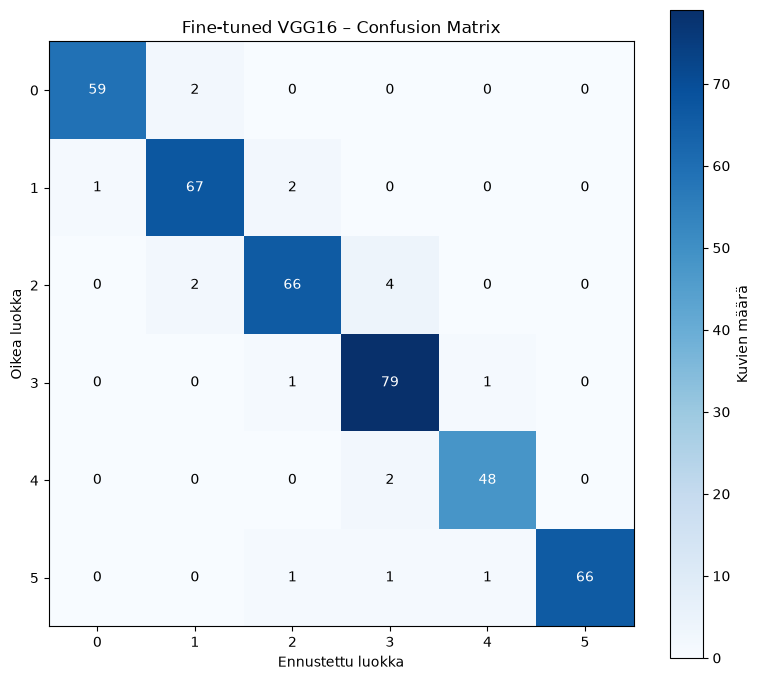

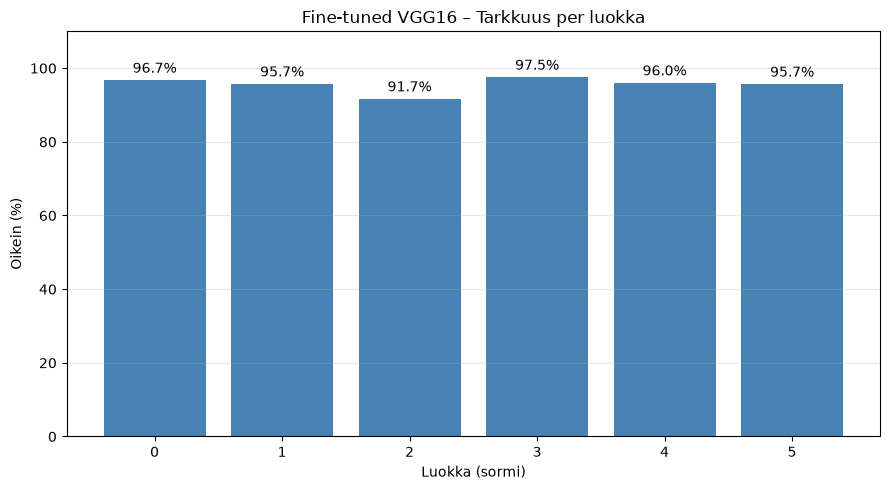


Luokka | Oikein | Yhteensä | Tarkkuus
---------------------------------------------
     0  |    59  |     61   |   96.7%
     1  |    67  |     70   |   95.7%
     2  |    66  |     72   |   91.7%
     3  |    79  |     81   |   97.5%
     4  |    48  |     50   |   96.0%
     5  |    66  |     69   |   95.7%


In [19]:
import matplotlib.pyplot as plt

all_probs = []
all_true = []
all_images = []

for images, labels in test_dataset:
    probs = model_ft.predict(images, verbose=0)
    all_probs.append(probs)
    all_true.append(labels.numpy())
    all_images.append(images.numpy())

y_probs = np.concatenate(all_probs)
y_true = np.concatenate(all_true)
y_pred = np.argmax(y_probs, axis=1)
x_test = np.concatenate(all_images) 

print(f"Kuvia: {len(y_true)}")
print(f"Oikein: {np.sum(y_true == y_pred)} / {len(y_true)}")
print(f"Test accuracy: {np.mean(y_true == y_pred) * 100:.2f}%")

# Confusion matrix
cm = np.zeros((num_classes, num_classes), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("Ennustettu luokka")
ax.set_ylabel("Oikea luokka")
ax.set_title("Fine-tuned VGG16 – Confusion Matrix")
fig.colorbar(im, ax=ax, label="Kuvien määrä")
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )
plt.tight_layout()
plt.show()

# Luokkakohtaiset tarkkuudet
correct = np.zeros(num_classes, dtype=int)
total = np.zeros(num_classes, dtype=int)
for i in range(num_classes):
    mask = (y_true == i)
    total[i] = np.sum(mask)
    correct[i] = np.sum(y_pred[mask] == i)

accuracy = np.divide(
    correct, total,
    out=np.zeros(num_classes, dtype=float),
    where=total != 0
) * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(class_names, accuracy, color="steelblue")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Luokka (sormi)")
ax.set_ylabel("Oikein (%)")
ax.set_title("Fine-tuned VGG16 – Tarkkuus per luokka")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nLuokka | Oikein | Yhteensä | Tarkkuus")
print("-" * 45)
for i in range(num_classes):
    print(f"  {class_names[i]:>4}  |  {correct[i]:>4}  |   {total[i]:>4}   |  {accuracy[i]:>5.1f}%")

Confusion matrixista näkee, että virheet keskittyvät vierekkäisiin luokkiin. Kaikki luokkakohtaiset tarkkuudet ovat yli 90 %: paras on luokka 3 (97.5 %) ja heikoin luokka 2 (91.7 %). FE-mallin heikoimmat luokat 4 ja 1 paranivat selvästi (80.0 %:sta 96.0 %:iin ja 82.9 %:sta 95.7 %:iin). Fine-tuning paransi siis selkeästi samankaltaisten sormimäärien erottelua.

### 4.3 Väärin luokitellut kuvat

Näytetään satunnaisotos väärin luokitelluista testikuvista. Kuvista näkee,
menevätkö virheet vierekkäisiin sormimääriin.

Väärin luokiteltuja: 18 / 403


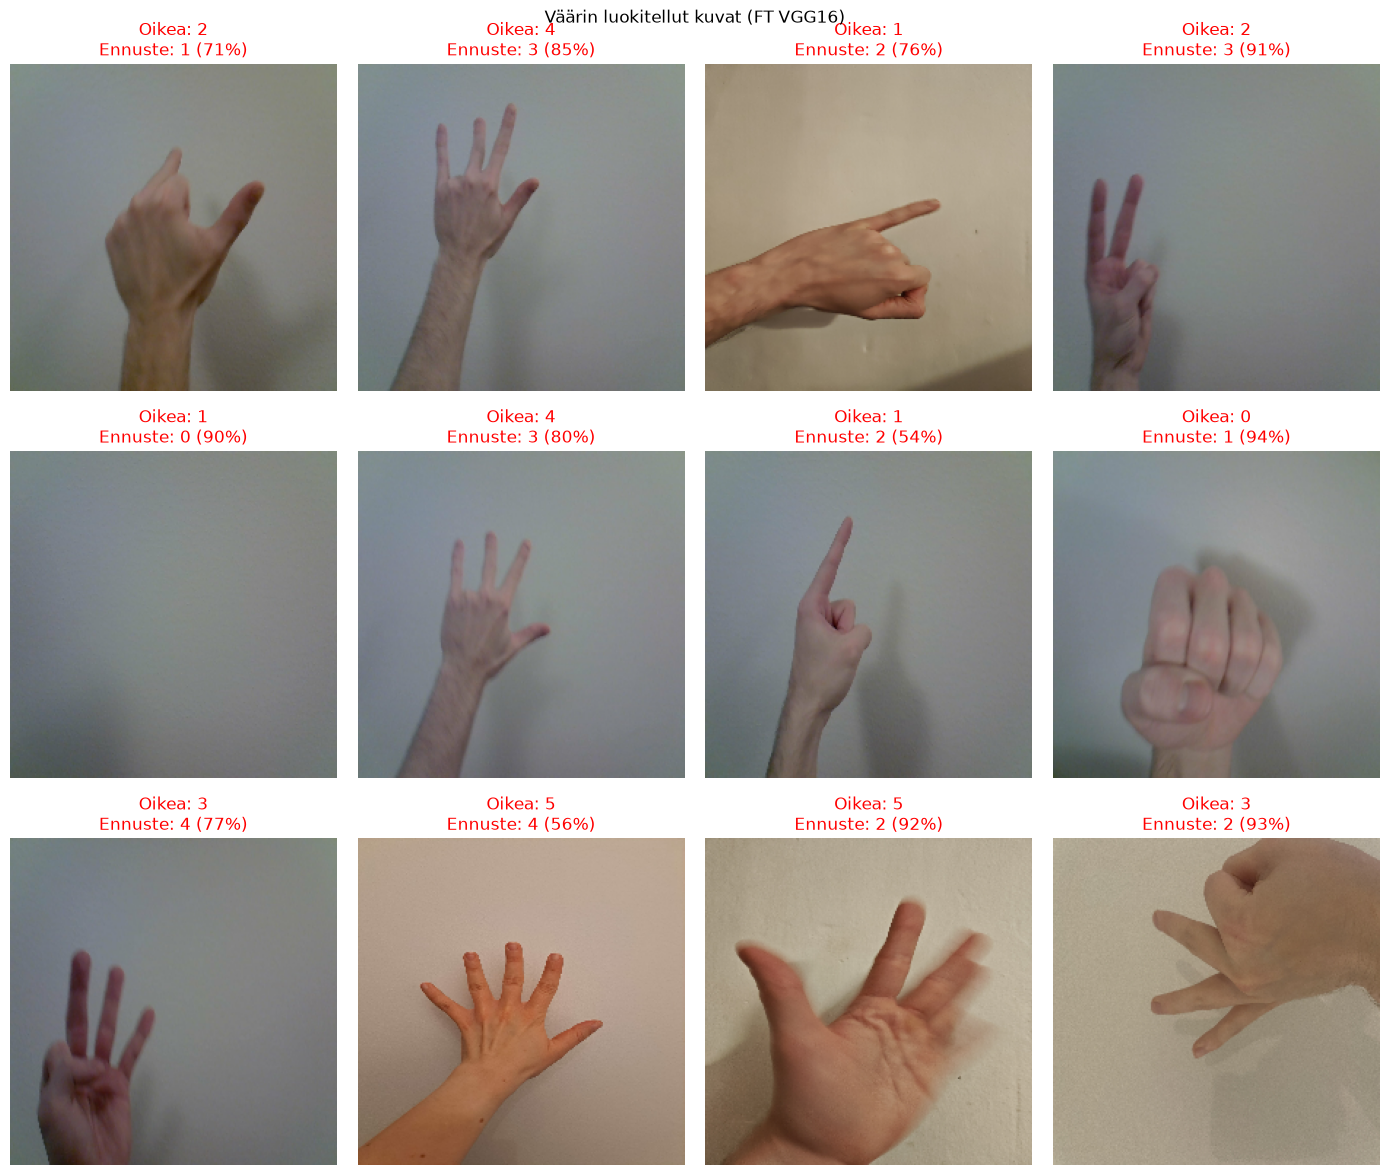

In [20]:
wrong_idx = np.where(y_true != y_pred)[0]
print(f"Väärin luokiteltuja: {len(wrong_idx)} / {len(y_true)}")

rng = np.random.default_rng(0)
show_idx = rng.choice(wrong_idx, size=min(12, len(wrong_idx)), replace=False)

n_cols = 4
n_rows = (len(show_idx) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, idx in enumerate(show_idx):
    ax = axes[i]
    ax.imshow(x_test[idx].astype("uint8"))
    true_class = int(y_true[idx])
    pred_class = int(y_pred[idx])
    conf = y_probs[idx][pred_class]
    ax.set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[pred_class]} ({conf:.0%})",
        color="red"
    )
    ax.axis("off")

for j in range(len(show_idx), len(axes)):
    axes[j].axis("off")

plt.suptitle("Väärin luokitellut kuvat (FT VGG16)")
plt.tight_layout(h_pad=3.0, w_pad=1.5)
plt.show()

Väärin luokiteltuja kuvia on 18 / 403 eli noin 4.5 %. Määrä on pieni, joten yksittäisistä virheistä ei voi tehdä vahvoja johtopäätöksiä. Virheet näyttävät keskittyvän vierekkäisiin sormimääriin, ja myös kätisyys, sormien asento sekä valaistus voivat vaikuttaa. Vähäinen virhemäärä tukee sitä, että fine-tuning paransi mallin erottelukykyä.

### 4.4 Yksittäisen kuvan ennuste

Näytetään kolme satunnaista testikuvaa ja niiden ennustetodennäköisyydet.

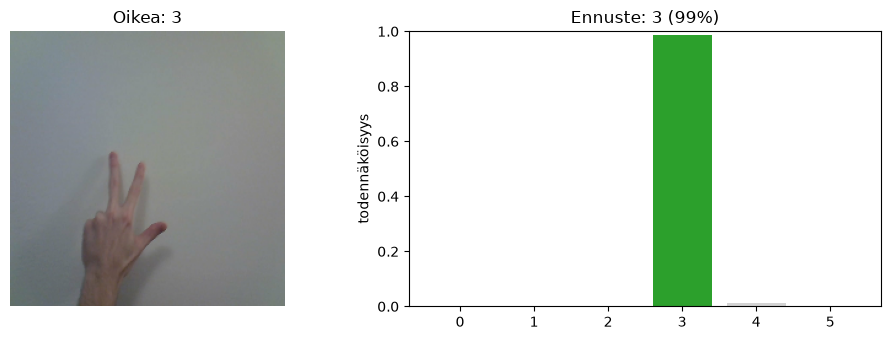

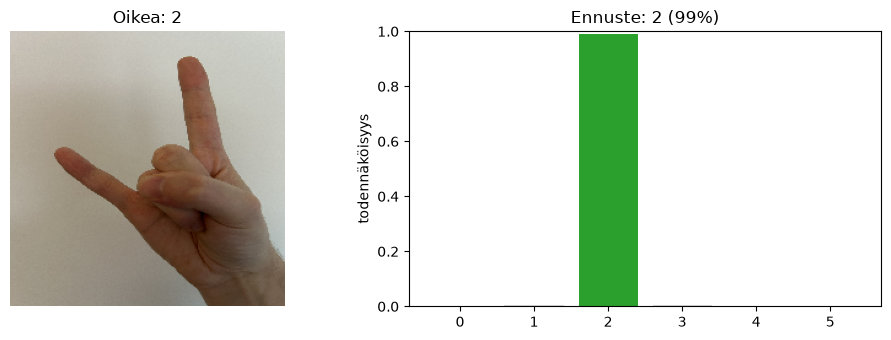

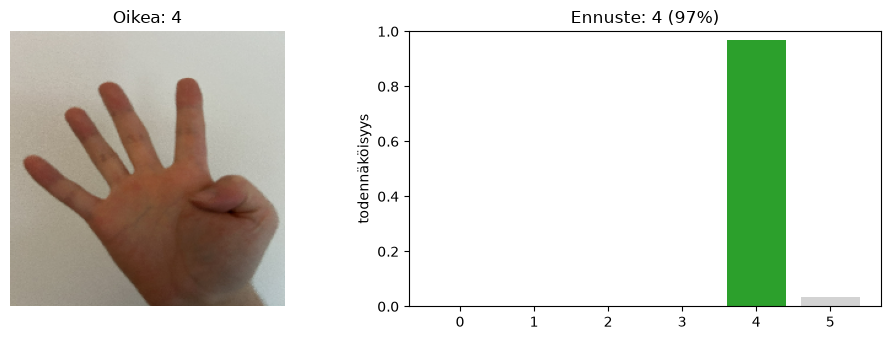

In [21]:
def plot_prediction(idx):
    pred = int(y_pred[idx])
    true = int(y_true[idx])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(x_test[idx].astype("uint8"))
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * num_classes
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(num_classes), y_probs[idx], color=colors)
    ax2.set_xticks(range(num_classes))
    ax2.set_xticklabels(class_names, rotation=0)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({y_probs[idx][pred]:.0%})")

    plt.tight_layout()
    plt.show()

# Näytetään 3 satunnaista testikuvaa
rng2 = np.random.default_rng(1)
for idx in rng2.choice(len(y_true), size=3, replace=False):
    plot_prediction(idx)

Kaikki kolme esimerkkiä menivät oikein, ja ennustetodennäköisyydet olivat 99 %, 99 % ja 97 %. Otos on vain kolme kuvaa, joten tämä ei yksinään kerro mallin yleisestä varmuudesta, koko testijoukolla tarkkuus oli 95.53 %. Korkea varmuus on silti linjassa sen kanssa, että fine-tuning paransi erottelukykyä FE-malliin verrattuna.

### 4.5 Classification report

Yhteenveto per luokka: precision, recall ja F1-score.

In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9833    0.9672    0.9752        61
           1     0.9437    0.9571    0.9504        70
           2     0.9429    0.9167    0.9296        72
           3     0.9186    0.9753    0.9461        81
           4     0.9600    0.9600    0.9600        50
           5     1.0000    0.9565    0.9778        69

    accuracy                         0.9553       403
   macro avg     0.9581    0.9555    0.9565       403
weighted avg     0.9562    0.9553    0.9554       403



Kaikkien luokkien precision, recall ja F1-score ovat korkeita. Heikoimmat F1-arvot ovat luokilla 2 (0.9296) ja 3 (0.9461), mutta erot luokkien välillä ovat pieniä. FE-malliin verrattuna luokkien 2 ja 3 tunnusluvut paranivat selvästi. Mikään luokka ei jää selvästi heikommaksi.

### 4.6 Koulutuskäyrät

Nähdään, miten loss ja accuracy kehittyivät fine-tuningin aikana.

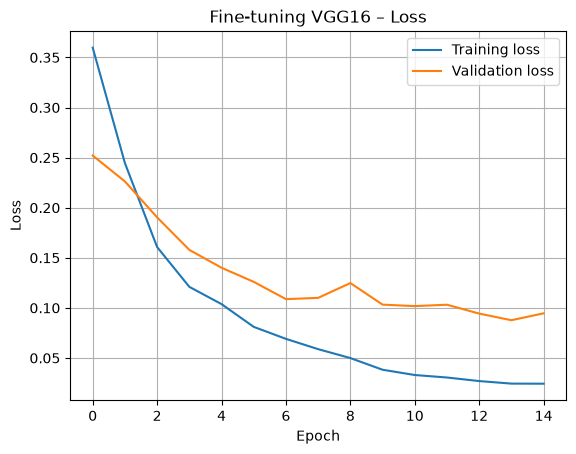

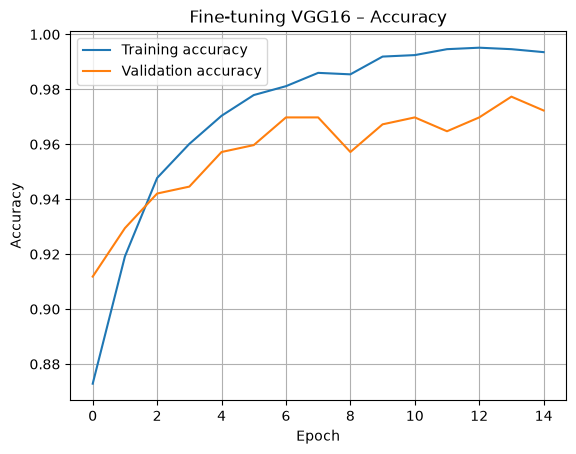

In [23]:
plt.plot(history_ft.history["loss"], label="Training loss")
plt.plot(history_ft.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-tuning VGG16 – Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history_ft.history["accuracy"], label="Training accuracy")
plt.plot(history_ft.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-tuning VGG16 – Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Kuvista näkee, että training-käyrä ohittaa validation-käyrän heti ensimmäisen epookin jälkeen: training loss laskee validation lossin alle ja training accuracy nousee validation accuracyn yli. Malli oppii harjoitusdatan nopeasti. Validation-käyrät kuitenkin tasaantuvat ja heiluvat hieman loppua kohden, mikä viittaa lievään ylisovittumiseen. Parhaaksi valittiin epokki 14, jossa val_loss oli 0.0877 ja val_accuracy 97.73 %. Näillä painoilla test accuracy oli 95.53 %.

### 4.7 Vertailu: Feature Extraction vs. Fine-tuning

Vedetään yhteen FE- ja FT-mallien testitulokset ja katsotaan, kuinka paljon fine-tuning paransi tulosta.
FE-luvut saadaan samasta ajosta, joten vertailu on suora.

In [24]:
print("Feature Extraction:")
print(f"  test loss:     {test_loss_fe:.4f}")
print(f"  test accuracy: {test_acc_fe * 100:.2f} %")

print("\nFine-tuned:")
print(f"  test loss:     {test_loss_ft:.4f}")
print(f"  test accuracy: {test_acc_ft * 100:.2f} %")

print("\nErot:")
print(f"  accuracy parani {(test_acc_ft - test_acc_fe) * 100:+.2f} prosenttiyksikköä")
print(f"  loss muuttui {(test_loss_ft - test_loss_fe):+.4f}")

Feature Extraction:
  test loss:     0.3863
  test accuracy: 88.59 %

Fine-tuned:
  test loss:     0.1407
  test accuracy: 95.53 %

Erot:
  accuracy parani +6.95 prosenttiyksikköä
  loss muuttui -0.2456


Fine-tuning paransi testitarkkuutta 6.94 prosenttiyksikköä (88.59 % -> 95.53 %) ja pienensi häviötä yli puoleen (0.3863 -> 0.1407). Koska FE- ja FT-malli arvioitiin samalla testijoukolla, vertailu on reilu. Ylimmän konvoluutioblokin avaaminen oli siis hyödyllistä tälle dataselille.

In [25]:
import json
import pandas as pd

metrics_ft = {
    "model": "fine_tuned_vgg16",
    "image_size": 224,
    "class_names": list(class_names),
    "test_loss": float(test_loss_ft),
    "test_accuracy": float(test_acc_ft),
    "confusion_matrix": cm.tolist(),
    "per_class_accuracy": accuracy.tolist(),
    "per_class_correct": correct.tolist(),
    "per_class_total": total.tolist(),
    # FE-baseline samasta ajosta vertailua varten
    "fe_baseline_loss": float(test_loss_fe),
    "fe_baseline_accuracy": float(test_acc_fe),
}
with open("metrics_ft.json", "w") as f:
    json.dump(metrics_ft, f, indent=2)

pd.DataFrame(history_ft.history).to_csv("history_ft.csv", index=False)

np.savez(
    "test_predictions_ft.npz",
    y_true=y_true,
    y_pred=y_pred,
    y_probs=y_probs,
)

print("Tallennettu: metrics_ft.json, history_ft.csv, test_predictions_ft.npz")

Tallennettu: metrics_ft.json, history_ft.csv, test_predictions_ft.npz
